# [F5 Facteurs de risque d'un portefeuille]




**Nom et prénom :** Oujedid Meryem   **Code Apogée :** 25007570    **Groupe :** G3    **Filière :** S7 FIN     **Date :** 17/11/2026




**Dépôt GitHub :** https://github.com/oujedidmeryem4290encg-lgtm/25007570-Oujedid-G3




## 1. Sujet et problématique
- **Intérêt du sujet** (2 à 3 lignes) : Un portefeuille est exposé à plusieurs sources de risque systématique (marché, taille, valeur), difficiles à séparer à l’œil nu. Mesurer ces expositions (les bêtas) et la part de rendement non expliquée (l’alpha) permet de comprendre le style du portefeuille, de juger si une surperformance vient d’une compétence ou du simple risque pris, et de mieux gérer ce risque.
- **Problématique** (une question) : Les rendements mensuels en excès d’un portefeuille équipondéré de grandes valeurs technologiques américaines s’expliquent-ils mieux par le modèle à trois facteurs de Fama-French (marché, taille, valeur) que par le CAPM seul, et son alpha est-il significativement différent de zéro ?
- **Objectif mesurable** (métrique, référence, période de test, seuil) : **Métrique**: R² ajusté dans l’échantillon, R² hors échantillon et RMSE de test. On y ajoute la p-value et l’intervalle de confiance à 95 % de l’alpha.
**Référence** : un modèle sans facteur (rendement moyen), puis le CAPM à un facteur.
**Période de test** : données mensuelles de 2015 à 2025, avec un découpage chronologique 75 % / 25 % (environ 2015-2022 pour l’estimation, 2023-2025 pour le test), sans mélange aléatoire.
**Seuil** : le modèle à trois facteurs est retenu si son R² hors échantillon est supérieur à celui du CAPM et à 0, et si le test F des modèles emboîtés (SMB et HML ajoutés au CAPM) a une p-value < 0,05.
- **Nature du problème** (et pourquoi) : Régression linéaire multiple, supervisée, à visée explicative. La cible (rendement en excès du portefeuille) est une valeur réelle, pas une classe. On cherche surtout à estimer et tester des coefficients (bêtas, alpha), plus qu’à prédire.
- **Algorithme principal envisagé** (n° de l'annexe A) : n° 1, Régression linéaire (moindres carrés ordinaires), avec erreurs robustes de Newey-West (HAC) pour vérifier la robustesse des tests. Les n° 2 (Ridge) et n° 3 (Lasso) pourraient servir de comparaison si les facteurs s’avéraient très corrélés.




## 2. Jeu de données
## 3. Exploration
## 4. Préparation
## 5. Algorithme
## 6. Protocole expérimental
## 7. Résultats
## 8. Analyse critique
## 9. Conclusion
## 10. Références et reproduction
## Déclaration des ressources et outils d'IA


# 2. Description du jeu de données


**Nom et source**
- **Facteurs** : « Fama/French 3 Factors » (fichier `F-F_Research_Data_Factors`), Kenneth R. French, Data Library, Tuck School of Business, Dartmouth.
  - Page : https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html
  - Fichier : https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/F-F_Research_Data_Factors_CSV.zip
  - Date d'extraction : 17 novembre 2026 (fichier créé avec la base CRSP 2026-09).
- **Prix des titres** : cours mensuels ajustés (dividendes et divisions inclus), via `yfinance` (Yahoo Finance), `interval="1mo"`, `auto_adjust=True`, du 2014-12-01 au 2025-12-31. Date d'extraction : 17 novembre 2026.


**Conditions d'utilisation**
- **Fama-French** : mention « Copyright 2026 Eugene F. Fama and Kenneth R. French ». Aucune licence explicite n'est indiquée. Données en accès libre pour la recherche et l'enseignement, avec citation de la source (Fama et French, 1993, *Journal of Financial Economics*).
- **Yahoo Finance** : aucune licence ouverte n'est indiquée dans les données ; les conditions de Yahoo limitent l'usage à des fins personnelles et non commerciales. Usage ici pédagogique, sans redistribution des données brutes.


**Taille, période, fréquence**
- **Fichier Fama-French complet** : 1 203 mois (juillet 1926 à septembre 2026), 4 variables numériques plus la date. Le tableau annuel présent dans le fichier est écarté (seules les dates AAAAMM sont gardées).
- **Échantillon utilisé** : janvier 2015 à décembre 2025, soit environ 132 observations mensuelles. Valeur exacte : voir la cellule de code ci-dessous (à reporter ici : N = ...).
- **Fréquence** : mensuelle ; rendements en pourcentage.


**Unité d'observation** : une ligne = un mois calendaire (clé `Date`, format AAAAMM) avec le rendement du portefeuille et les trois facteurs de ce mois.


**Dictionnaire des variables**
| Variable | Description | Type | Unité | Rôle | Manquants (%) |
|---|---|---|---|---|---|
| `Date` | Mois (AAAAMM) | date (texte) | mois | clé de fusion | 0 |
| `Mkt-RF` | Rendement du marché américain moins le taux sans risque | numérique | % / mois | explicative | 0 |
| `SMB` | Small Minus Big : petites moins grandes capitalisations | numérique | % / mois | explicative | 0 |
| `HML` | High Minus Low : titres « valeur » moins titres « croissance » | numérique | % / mois | explicative | 0 |
| `RF` | Taux sans risque (bon du Trésor à 1 mois) | numérique | % / mois | auxiliaire (construction de la cible) | 0 |
| `Portefeuille` (créée) | Moyenne des rendements mensuels des 5 titres (AAPL, MSFT, GOOGL, AMZN, META) : `pct_change() × 100`, poids 1/5 | numérique | % / mois | intermédiaire | voir cellule de code |
| `Rp_exc` (créée) | `Portefeuille − RF` | numérique | % / mois | **cible** | voir cellule de code |


**Variable cible** : `Rp_exc` = rendement mensuel du portefeuille − taux sans risque, en %. Portefeuille équipondéré, rééquilibré chaque mois. Les tickers sont un exemple à remplacer par votre sélection.


**Adéquation à la problématique**
- Les trois facteurs sont les variables explicatives du modèle de Fama-French et `Rp_exc` est la cible de la régression.
- Les facteurs sont publics et référencés, donc reproductibles.
- Environ 130 observations mensuelles suffisent pour estimer 4 paramètres (alpha et 3 bêtas), tester l'alpha et faire un découpage chronologique 75 % / 25 %.


**Limites**
- **Biais de survie et de sélection** : les 5 titres sont des gagnantes actuelles choisies après coup, ce qui gonfle l'alpha. Les entreprises disparues ou en déclin sont absentes.
- **Concentration et représentativité** : 5 grandes valeurs technologiques ; résultat non généralisable au marché.
- **Taille de l'échantillon** : environ 130 mois, dont environ 33 pour le test ; le R² hors échantillon est très bruité.
- **Révisions** : CRSP révise parfois les séries ; le taux sans risque change de source en juin 2024 (Ibbotson jusqu'à mai 2024, puis ICE BofA). D'où la date d'extraction.
- **Données Yahoo** : source non officielle, sujette à des ajustements rétroactifs et à un dernier mois possiblement incomplet.
- **Changements de régime** : la période inclut le Covid et la hausse des taux de 2022 ; les coefficients peuvent ne pas être constants (fenêtre glissante, section 7.2).
- **Modèle** : seulement 3 facteurs (pas de momentum, rentabilité ni investissement) ; frais de transaction ignorés.


In [91]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [92]:
df = pd.read_csv("/content/drive/MyDrive/data raw/F-F_Research_Data_Factors.csv",skiprows=3)
print(df)

                                             Unnamed: 0   Mkt-RF      SMB  \
0                                                192607     2.89    -2.42   
1                                                192608     2.64    -1.44   
2                                                192609     0.38    -1.36   
3                                                192610    -3.27    -0.18   
4                                                192611     2.54    -0.17   
...                                                 ...      ...      ...   
1300                                               2022   -21.32    -6.99   
1301                                               2023    21.75    -3.53   
1302                                               2024    19.76   -11.31   
1303                                               2025    13.30   -10.79   
1304  Copyright 2026 Eugene F. Fama and Kenneth R. F...      NaN      NaN   

          HML       RF  
0       -2.75     0.22  
1        4.13     0.25  


In [93]:
import io, pandas as pd

with open("/content/drive/MyDrive/data raw/F-F_Research_Data_Factors.csv", encoding="latin-1") as f:
    texte = f.read()

lignes = [l for l in texte.splitlines()
          if len(l.split(",")[0].strip()) == 6 and l.split(",")[0].strip().isdigit()]
ff = pd.read_csv(io.StringIO("Date,Mkt-RF,SMB,HML,RF\n" + "\n".join(lignes)))
ff["Date"] = ff["Date"].astype(str).str.strip()
ff = ff.dropna().reset_index(drop=True)
print(ff.shape, ff["Date"].min(), "->", ff["Date"].max())   # attendu : (1203, 5) 192607 -> 202609

(1203, 5) 192607 -> 202609


In [94]:
import yfinance as yf
import pandas as pd

tickers_list = ["AAPL", "MSFT", "GOOGL", "AMZN", "META"]   # à adapter à votre portefeuille
poids = pd.Series(1 / len(tickers_list), index=tickers_list)

prix = yf.download(tickers_list, start="2014-12-01", end="2025-12-31",
                   interval="1mo", auto_adjust=True, progress=False)["Close"][tickers_list]

rend = prix.pct_change().dropna(how="all") * 100
rend["Portefeuille"] = (rend[tickers_list] * poids).sum(axis=1)

rend.index = pd.to_datetime(rend.index).strftime("%Y%m")
rend = rend.rename_axis("Date").reset_index()
print(rend.shape)
rend.head()

(132, 7)


Ticker,Date,AAPL,MSFT,GOOGL,AMZN,META,Portefeuille
0,201501,6.142412,-13.024719,1.298363,14.235538,-2.704452,1.189429
1,201502,10.077629,9.311977,4.665621,7.229289,4.031107,7.063124
2,201503,-3.137163,-7.274774,-1.409447,-2.120159,4.115499,-1.965209
3,201504,0.578643,19.626185,-1.069046,13.351256,-4.196083,5.658191
4,201505,4.533912,-3.033440,-0.628677,1.766321,0.533227,0.634269


In [95]:
data = pd.merge(rend, ff, on="Date", how="inner")
data["Rp_exc"] = data["Portefeuille"] - data["RF"]
data = data.dropna(subset=["Rp_exc", "Mkt-RF", "SMB", "HML"]).reset_index(drop=True)

print("Observations (mois) :", len(data))
print("Période :", data["Date"].min(), "->", data["Date"].max())
print("Variables du fichier Fama-French :", ff.shape[1] - 1, "(hors date)")
print("\nValeurs manquantes (%) :")
print((data[["Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]].isna().mean() * 100).round(2))
print("\nFichier complet :", len(ff), "mois | de", ff["Date"].min(), "à", ff["Date"].max())

Observations (mois) : 132
Période : 201501 -> 202512
Variables du fichier Fama-French : 4 (hors date)

Valeurs manquantes (%) :
Portefeuille    0.0
RF              0.0
Rp_exc          0.0
Mkt-RF          0.0
SMB             0.0
HML             0.0
dtype: float64

Fichier complet : 1203 mois | de 192607 à 202609


In [96]:
# Vérification du jeu fusionné : dimensions, types, premières lignes, plage de dates et fréquence
print("Dimensions (lignes, colonnes) :", data.shape)
print("\nTypes :")
print(data[["Date", "Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]].dtypes)

dates = pd.to_datetime(data["Date"], format="%Y%m")
print("\nPériode :", dates.min().strftime("%Y-%m"), "->", dates.max().strftime("%Y-%m"))

# Fréquence : écart (en mois) entre deux dates consécutives ; tout doit valoir 1
ecarts = dates.dt.to_period("M").diff().dropna().apply(lambda d: d.n)
print("Écarts entre dates consécutives (mois) :", ecarts.value_counts().to_dict(), "-> fréquence mensuelle" if (ecarts == 1).all() else "-> ATTENTION : trous dans le calendrier")

data[["Date", "Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]].head()

Dimensions (lignes, colonnes) : (132, 12)

Types :
Date             object
Portefeuille    float64
RF              float64
Rp_exc          float64
Mkt-RF          float64
SMB             float64
HML             float64
dtype: object

Période : 2015-01 -> 2025-12
Écarts entre dates consécutives (mois) : {1: 131} -> fréquence mensuelle


,Date,Portefeuille,RF,Rp_exc,Mkt-RF,SMB,HML
0,201501,1.189429,0.0,1.189429,-3.10,-0.61,-3.48
1,201502,7.063124,0.0,7.063124,6.13,0.64,-1.75
2,201503,-1.965209,0.0,-1.965209,-1.11,3.06,-0.38
3,201504,5.658191,0.0,5.658191,0.59,-2.98,1.81
4,201505,0.634269,0.0,0.634269,1.37,0.96,-1.10


Les dimensions donnent le nombre de mois exploitables (une ligne = un mois). Tous les écarts valent 1 : le calendrier est mensuel et sans trou, ce qui est nécessaire avant tout découpage chronologique. Les colonnes numériques sont bien de type `float64` ; seule `Date` est du texte (clé de fusion AAAAMM). *(Complétez avec vos chiffres : N = …, période = … à ….)*

# 3. Exploration des données

## 3.1 Statistiques descriptives

On résume les variables utiles au problème : la cible `Rp_exc` et les trois facteurs. Outre la moyenne et l'écart-type, on calcule l'**asymétrie** (*skewness*) et le **kurtosis** (excès), qui mesurent l'épaisseur des queues : ils conditionnent la fiabilité des tests de la régression.

In [97]:
VARS = ["Rp_exc", "Mkt-RF", "SMB", "HML"]

desc = data[VARS].describe().T
desc["asymétrie"] = data[VARS].skew()
desc["kurtosis (excès)"] = data[VARS].kurt()
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,asymétrie,kurtosis (excès)
Rp_exc,132.0,2.03,6.15,-14.25,-1.97,2.61,6.08,18.94,-0.14,-0.04
Mkt-RF,132.0,0.99,4.48,-13.37,-1.54,1.36,3.40,13.60,-0.35,0.78
SMB,132.0,-0.18,2.75,-5.93,-2.30,-0.20,1.24,7.14,0.40,-0.06
HML,132.0,-0.11,3.72,-13.83,-2.21,-0.50,1.88,12.86,0.21,1.81


Sur 132 mois, le rendement mensuel en excès du portefeuille a une moyenne de 2,03 % (environ 27 % par an) pour un écart-type de 6,15 %. Le marché affiche 0,99 % de moyenne et 4,48 % d’écart-type : le portefeuille rapporte environ deux fois plus mais fluctue environ 1,4 fois plus, ce qui annonce un bêta de marché supérieur à 1. Ce rendement élevé est à relativiser : le portefeuille est composé de gagnantes actuelles choisies après coup (biais de survie, section 2).

La distribution de Rp_exc est quasi symétrique (asymétrie −0,14) et sans queues épaisses (kurtosis −0,04), proche d’une loi normale, avec des extrêmes de −14,25 % et +18,94 %. En revanche, HML (kurtosis 1,81) et Mkt-RF (0,78) ont des queues plus épaisses que la loi normale, c’est-à-dire des mois extrêmes plus fréquents. Les résidus de la régression ne sont donc pas garantis normaux

## 3.2 Qualité des données

Pour chaque problème potentiel, on indique la méthode de détection, la décision prise et sa justification.

In [98]:
# 1) Valeurs manquantes
cols = ["Portefeuille", "RF", "Rp_exc", "Mkt-RF", "SMB", "HML"]
print("Valeurs manquantes par colonne :")
print(data[cols].isna().sum().to_string())

# 2) Doublons : une seule ligne par mois
print("\nDates en double :", int(data["Date"].duplicated().sum()))
print("Lignes entièrement identiques :", int(data.duplicated().sum()))

# 3) Valeurs atypiques : règle |z| > 3 (détection seulement, rien n'est modifié ici)
z = (data[VARS] - data[VARS].mean()) / data[VARS].std()
masque = z.abs() > 3
print("\nNombre de valeurs |z| > 3 par variable :")
print(masque.sum().to_string())

atypiques = data.loc[masque.any(axis=1), ["Date"] + VARS].round(2)
print("\nMois atypiques :")
print(atypiques.to_string(index=False) if len(atypiques) else "aucun")

# Contrôle complémentaire par la règle de l'écart interquartile (IQR) sur la cible
q1, q3 = data["Rp_exc"].quantile([0.25, 0.75])
iqr = q3 - q1
borne_bas, borne_haut = q1 - 1.5 * iqr, q3 + 1.5 * iqr
n_iqr = int(((data["Rp_exc"] < borne_bas) | (data["Rp_exc"] > borne_haut)).sum())
print(f"\nRègle IQR sur Rp_exc : bornes [{borne_bas:.1f} ; {borne_haut:.1f}] % -> {n_iqr} mois hors bornes")

Valeurs manquantes par colonne :
Portefeuille    0
RF              0
Rp_exc          0
Mkt-RF          0
SMB             0
HML             0

Dates en double : 0
Lignes entièrement identiques : 0

Nombre de valeurs |z| > 3 par variable :
Rp_exc    0
Mkt-RF    1
SMB       0
HML       2

Mois atypiques :
  Date  Rp_exc  Mkt-RF   SMB    HML
202003   -6.66  -13.37 -4.69 -13.83
202201   -6.57   -6.16 -5.93  12.86

Règle IQR sur Rp_exc : bornes [-14.1 ; 18.2] % -> 2 mois hors bornes


| Problème | Méthode de détection | Décision | Justification |
|---|---|---|---|
| Valeurs manquantes | `isna().sum()` par colonne | *(aucune à ce stade, à confirmer)*. Les lignes incomplètes éventuelles sont retirées par `dropna` (section 2) | Un mois sans rendement ou sans facteur ne peut pas entrer dans la régression ; on ne les impute pas, pour ne pas inventer de rendements |
| Doublons | `duplicated()` sur `Date` et sur la ligne entière | *(aucun, à confirmer)* | La fusion interne sur une clé unique ne crée pas de doublon |
| Trous dans le calendrier | écart d'un mois entre dates consécutives (section 2) | *(aucun, à confirmer)* | Une série mensuelle sans trou est nécessaire pour la fenêtre glissante et le découpage chronologique |
| Unités et échelles | lecture des ordres de grandeur (`describe`) | tout est en % mensuel | Évite de mélanger des rendements en % et en décimales |
| Valeurs atypiques | règle \|z\| > 3 et règle de l'IQR | **conservées** | En finance, une valeur extrême est le plus souvent réelle (krach de mars 2020, rebond d'avril 2020, etc.) : la supprimer biaiserait le risque estimé. On l'assume dans les limites et on utilise des erreurs robustes (HAC) |

## 3.3 Visualisations

### Graphique 1 : évolution de la cible dans le temps

Les mois atypiques (|z| > 3) sont entourés : on vérifie s'ils correspondent à des événements de marché connus.

In [99]:
import io, zipfile, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import statsmodels.api as sm
import yfinance as yf

np.random.seed(42)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

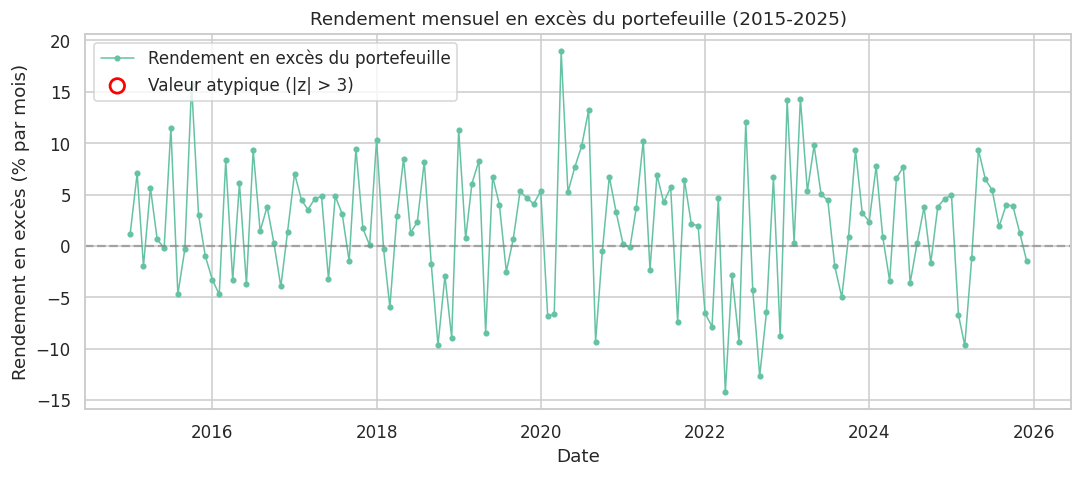

In [100]:
dates = pd.to_datetime(data["Date"], format="%Y%m")
atyp_idx = masque["Rp_exc"]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(dates, data["Rp_exc"], marker="o", markersize=3, linewidth=1, label="Rendement en excès du portefeuille")
ax.scatter(dates[atyp_idx], data.loc[atyp_idx, "Rp_exc"], s=90, facecolors="none",
           edgecolors="red", linewidths=1.8, label="Valeur atypique (|z| > 3)")
ax.axhline(0, color="grey", linestyle="--", alpha=0.6)
ax.set_title("Rendement mensuel en excès du portefeuille (2015-2025)")
ax.set_xlabel("Date")
ax.set_ylabel("Rendement en excès (% par mois)")
ax.legend()
plt.tight_layout()
plt.show()

Le rendement en excès oscille autour d'une moyenne positive, avec des mois très négatifs (début 2020, 2022) et des rebonds marqués. Les points entourés sont peu nombreux et coïncident avec des épisodes de stress de marché : ce sont des observations réelles, conservées.

### Graphique 2 : distribution de la cible

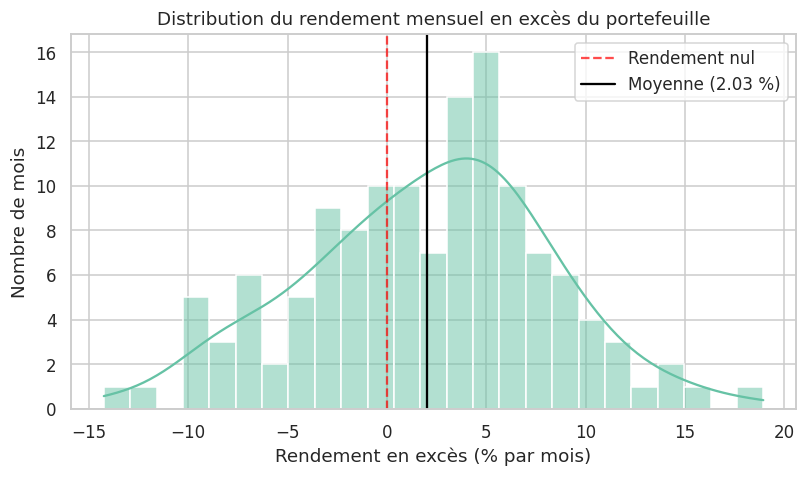

In [101]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sns.histplot(data["Rp_exc"], bins=25, kde=True, alpha=0.5, ax=ax)
ax.axvline(0, color="red", linestyle="--", alpha=0.7, label="Rendement nul")
ax.axvline(data["Rp_exc"].mean(), color="black", label=f"Moyenne ({data['Rp_exc'].mean():.2f} %)")
ax.set_title("Distribution du rendement mensuel en excès du portefeuille")
ax.set_xlabel("Rendement en excès (% par mois)")
ax.set_ylabel("Nombre de mois")
ax.legend()
plt.tight_layout()
plt.show()

La distribution est approximativement en cloche, centrée à droite de 0, avec des queues un peu plus épaisses qu'une loi normale (cohérent avec le kurtosis du 3.1). Les tests de la régression seront donc complétés par des erreurs robustes et un bootstrap.

### Graphique 3 : relation entre la cible et chaque facteur

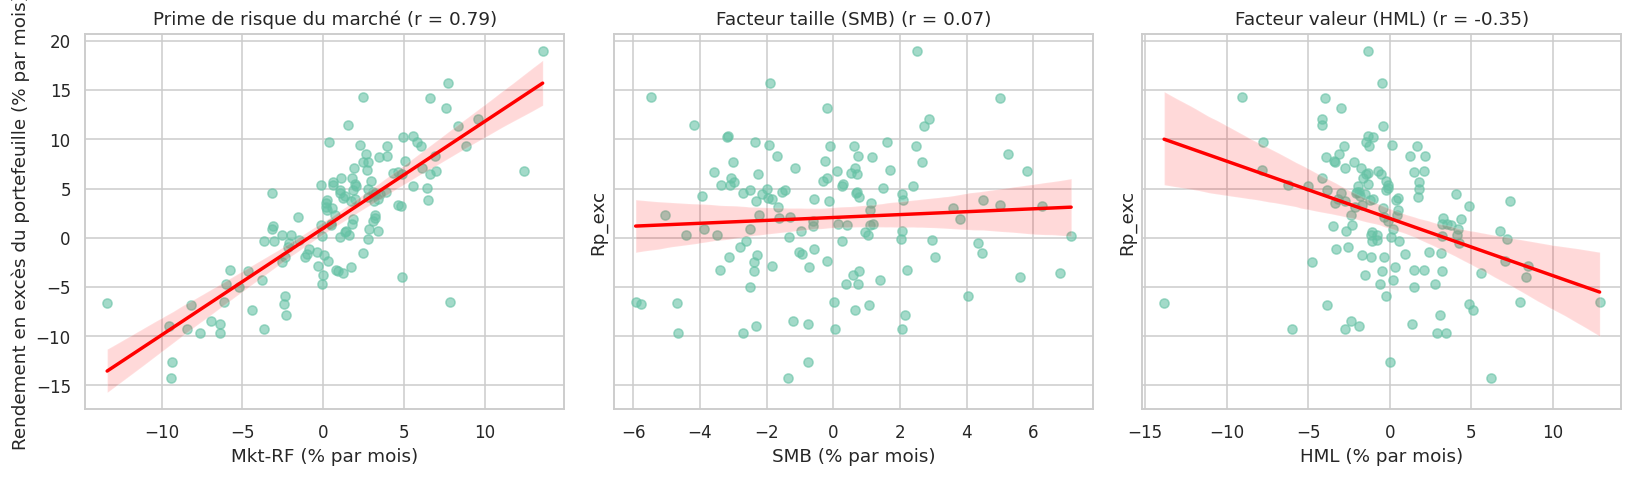

In [102]:
facteurs = ["Mkt-RF", "SMB", "HML"]
noms_f = {"Mkt-RF": "Prime de risque du marché", "SMB": "Facteur taille (SMB)", "HML": "Facteur valeur (HML)"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, f in zip(axes, facteurs):
    sns.regplot(data=data, x=f, y="Rp_exc", scatter_kws={"alpha": 0.6}, line_kws={"color": "red"}, ax=ax)
    r = data[[f, "Rp_exc"]].corr().iloc[0, 1]
    ax.set_title(f"{noms_f[f]} (r = {r:.2f})")
    ax.set_xlabel(f"{f} (% par mois)")
axes[0].set_ylabel("Rendement en excès du portefeuille (% par mois)")
plt.tight_layout()
plt.show()

Seule la prime de risque du marché montre une relation nette et croissante avec la cible (la pente est le bêta de marché). Les nuages SMB et HML sont beaucoup plus diffus : leur apport sera à tester (test F, section 7), pas à supposer.

### Graphique 4 : corrélations entre variables et multicolinéarité

Des facteurs très corrélés entre eux rendent les bêtas imprécis. On complète la matrice de corrélation par le **facteur d'inflation de la variance** (VIF) : une valeur supérieure à 5 à 10 signale un problème.

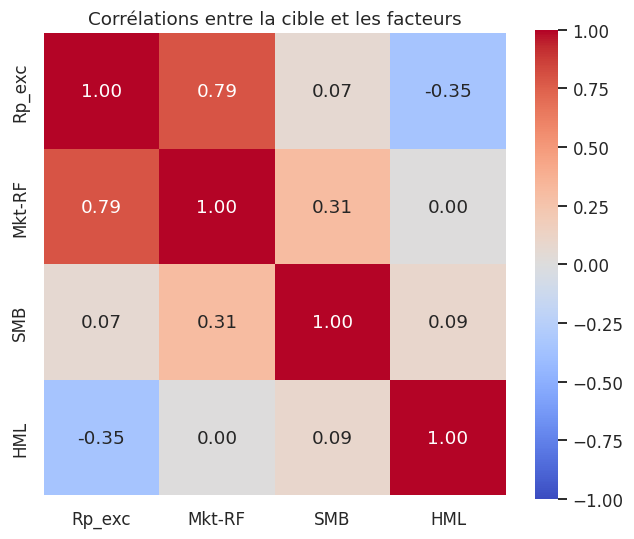

VIF des facteurs :
Mkt-RF    1.10
SMB       1.11
HML       1.01


In [103]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(data[VARS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Corrélations entre la cible et les facteurs")
plt.tight_layout()
plt.show()

Xv = sm.add_constant(data[facteurs])
vif = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])], index=facteurs)
print("VIF des facteurs :")
print(vif.round(2).to_string())

Les corrélations entre facteurs sont faibles à modérées et les VIF restent proches de 1 : il n'y a pas de multicolinéarité préoccupante, les trois bêtas peuvent être estimés séparément. Le recours à Ridge ou Lasso (n° 2 et 3 de l'annexe A) n'est donc pas nécessaire ici, mais reste possible en comparaison.

# 4. Préparation des données

Chaque étape est justifiée. Le problème est **explicatif et contemporain** : le rendement d'un mois est expliqué par les facteurs du **même** mois. Il n'y a donc ni retard, ni décalage de la cible vers le futur.

| Étape | Décision | Justification |
|---|---|---|
| Nettoyage | fusion interne sur `Date`, suppression des lignes incomplètes, tri chronologique | Garantit un mois = une ligne, sans trou ni doublon (section 3.2) |
| Création de variables | `Rp_exc = Portefeuille − RF` ; aucun retard ni moyenne glissante | La cible doit être un rendement **en excès** du taux sans risque. Les facteurs et la cible sont observés le même mois : un retard `shift(k)` changerait la question posée |
| Encodage | aucun | Toutes les variables explicatives sont numériques ; `Date` ne sert que de clé et d'axe du temps |
| Mise à l'échelle | **aucune pour les MCO** | Les MCO donnent les mêmes prédictions quelle que soit l'échelle, et garder les unités (% par mois) permet de lire les bêtas directement. Elle serait **nécessaire** pour Ridge/Lasso (pénalité sensible à l'échelle) : on l'ajusterait alors sur l'apprentissage seulement, dans un `Pipeline` |
| Découpage | chronologique 75 % / 25 %, sans mélange (`shuffle=False`) | Le test doit être postérieur à l'apprentissage ; un mélange aléatoire ferait « voir le futur » au modèle |
| Écart apprentissage/test | aucun | L'horizon de la cible est nul (même mois) : il n'y a pas de recouvrement entre les périodes |

In [104]:
GRAINE = 42
np.random.seed(GRAINE)

CIBLE = "Rp_exc"
FEATURES = ["Mkt-RF", "SMB", "HML"]

# Ordre chronologique garanti
data = data.sort_values("Date").reset_index(drop=True)
assert data["Date"].is_monotonic_increasing and not data["Date"].duplicated().any()

# Preuve de l'alignement : facteurs et cible du même mois, RF utilisé uniquement pour construire la cible
verif = data[["Date", "Portefeuille", "RF", "Rp_exc"] + FEATURES].head()
verif

,Date,Portefeuille,RF,Rp_exc,Mkt-RF,SMB,HML
0,201501,1.189429,0.0,1.189429,-3.10,-0.61,-3.48
1,201502,7.063124,0.0,7.063124,6.13,0.64,-1.75
2,201503,-1.965209,0.0,-1.965209,-1.11,3.06,-0.38
3,201504,5.658191,0.0,5.658191,0.59,-2.98,1.81
4,201505,0.634269,0.0,0.634269,1.37,0.96,-1.10


In [105]:
# Découpage chronologique 75 % / 25 % (le jeu de test n'est utilisé qu'une fois, en section 7)
n_train = int(0.75 * len(data))
X, y = data[FEATURES], data[CIBLE]
X_train, X_test = X.iloc[:n_train], X.iloc[n_train:]
y_train, y_test = y.iloc[:n_train], y.iloc[n_train:]

print(f"Apprentissage : {len(X_train)} mois, de {data['Date'].iloc[0]} à {data['Date'].iloc[n_train - 1]}")
print(f"Test          : {len(X_test)} mois, de {data['Date'].iloc[n_train]} à {data['Date'].iloc[-1]}")
assert data["Date"].iloc[n_train - 1] < data["Date"].iloc[n_train]   # le test est bien postérieur

Apprentissage : 99 mois, de 201501 à 202303
Test          : 33 mois, de 202304 à 202512


Le jeu de test commence après la fin de l'apprentissage : aucune information du futur n'est utilisée pour estimer le modèle. Les coefficients (alpha, bêtas) sont estimés sur l'apprentissage ; le jeu de test ne sert qu'à l'évaluation finale.

In [106]:
# Validation croisée respectant l'ordre du temps (utile si l'on règle un hyperparamètre, par exemple pour Ridge/Lasso)
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

tscv = TimeSeriesSplit(n_splits=5)
for k, (i_tr, i_va) in enumerate(tscv.split(X_train), start=1):
    print(f"Pli {k} : apprentissage = {len(i_tr)} mois | validation = {len(i_va)} mois (toujours postérieurs)")

# Pour un modèle pénalisé, la mise à l'échelle est dans le Pipeline : elle est réajustée sur chaque pli d'apprentissage
pipe_penalise = Pipeline([("echelle", StandardScaler()), ("modele", Ridge(alpha=1.0))])
pipe_penalise.fit(X_train, y_train)   # fit sur l'apprentissage seulement ; transform appliqué au test plus tard
print("\nMoyennes estimées par le StandardScaler (apprentissage uniquement) :",
      {f: round(float(m), 2) for f, m in zip(FEATURES, pipe_penalise.named_steps["echelle"].mean_)})

Pli 1 : apprentissage = 19 mois | validation = 16 mois (toujours postérieurs)
Pli 2 : apprentissage = 35 mois | validation = 16 mois (toujours postérieurs)
Pli 3 : apprentissage = 51 mois | validation = 16 mois (toujours postérieurs)
Pli 4 : apprentissage = 67 mois | validation = 16 mois (toujours postérieurs)
Pli 5 : apprentissage = 83 mois | validation = 16 mois (toujours postérieurs)

Moyennes estimées par le StandardScaler (apprentissage uniquement) : {'Mkt-RF': 0.87, 'SMB': -0.05, 'HML': -0.18}


Les plis de validation croisée s'enchaînent dans le temps : l'apprentissage précède toujours la validation. Le `StandardScaler` ne voit que l'apprentissage, donc aucune statistique du test ne fuit dans le modèle. Pour l'algorithme principal (MCO, n° 1), cette mise à l'échelle n'est pas utilisée : elle sert uniquement à l'éventuelle comparaison Ridge/Lasso.

## Contrôle des fuites de données

- **Découpage avant transformation** : aucune transformation apprise sur les données n'est appliquée avant le découpage. Le seul `fit` (StandardScaler) porte sur l'apprentissage.
- **Ordre du temps** : test postérieur à l'apprentissage, sans mélange ; validation croisée par `TimeSeriesSplit`.
- **Variables construites avec le passé seulement** : aucune variable retardée ni glissante dans le modèle principal ; les facteurs et la cible sont du même mois (problème contemporain, assumé).
- **Variables contenant la cible** : `RF` sert à construire la cible mais n'est pas explicative. Limite : `Mkt-RF` est un indice de tout le marché américain, qui contient en partie les cinq titres du portefeuille. Le lien est faible (5 titres sur plusieurs milliers) mais il existe.
- **Jeu de test** : utilisé une seule fois, en section 7. Nombre de configurations essayées : 1 pour les MCO *(à mettre à jour si vous testez Ridge/Lasso)*.
- **Révisions de données** : les facteurs Fama-French et les prix ajustés de Yahoo sont les versions **actuelles**, donc éventuellement révisées depuis leur première publication. C'est une limite, comme indiqué en section 2.

# 5. Algorithme

## 5.1 Choix de l'algorithme

**Algorithme principal : n° 1, Régression linéaire (moindres carrés ordinaires, MCO).**

**Pourquoi il convient :**
- **Nature de la tâche** : régression, la cible `Rp_exc` est une valeur réelle (section 1).
- **Taille des données** : 132 mois dont 99 pour l'apprentissage. C'est peu : un modèle à 4 paramètres est adapté, un modèle flexible surapprendrait.
- **Types de variables** : trois variables numériques, très peu corrélées entre elles (VIF proches de 1, section 3.3), donc pas de problème de multicolinéarité.
- **Relation attendue** : linéaire par construction du modèle de Fama-French, et compatible avec les nuages de points de la section 3.3.
- **Besoin d'interprétation** : fort. On veut lire des bêtas (expositions) et un alpha, avec intervalles de confiance et tests, ce que seul un modèle linéaire donne directement.

**Pourquoi pas les autres :**
- **Ridge / Lasso (n° 2 et 3)** : leur intérêt est de stabiliser ou de sélectionner des variables corrélées. Ici, il n'y a que trois variables, quasi indépendantes, et la pénalisation biaise les coefficients qu'on veut interpréter. Ridge est gardé comme **modèle de comparaison analysé** (section 7).
- **Forêt aléatoire, régression (n° 6)** : elle ne fournit ni coefficients ni tests, elle demande plus de données que 99 mois, et elle ne sait pas extrapoler au-delà des valeurs de facteurs déjà vues.

## 5.2 Principe de l'algorithme

**Intuition.** On cherche le plan qui passe « au mieux » parmi les observations : celui qui rend les écarts entre rendements observés et rendements prédits les plus petits possible, au sens des moindres carrés.

**Modèle :**

$$y_t = \alpha + \beta_1\,\mathrm{Mkt\text{-}RF}_t + \beta_2\,\mathrm{SMB}_t + \beta_3\,\mathrm{HML}_t + \varepsilon_t$$

**Estimation :**

$$\hat{\boldsymbol\theta} = \arg\min_{\boldsymbol\theta}\sum_{t=1}^{n}\left(y_t - \mathbf{x}_t^\top\boldsymbol\theta\right)^2 = (X^\top X)^{-1}X^\top \mathbf{y}$$

- $y_t$ : rendement en excès du portefeuille au mois $t$ (en %) ;
- $\mathbf{x}_t = (1,\ \mathrm{Mkt\text{-}RF}_t,\ \mathrm{SMB}_t,\ \mathrm{HML}_t)^\top$ : vecteur des facteurs du mois $t$, avec une constante ;
- $\boldsymbol\theta = (\alpha, \beta_1, \beta_2, \beta_3)^\top$ : paramètres, où $\alpha$ est le rendement non expliqué et $\beta_k$ l'exposition au facteur $k$ ;
- $X$ : matrice $n \times 4$ des $\mathbf{x}_t^\top$, $\mathbf{y}$ : vecteur des $n$ rendements ;
- $\varepsilon_t$ : erreur du modèle (résidu), de moyenne nulle.

**Étapes d'apprentissage :** (1) construire $X$ avec sa colonne de 1 ; (2) calculer $\hat{\boldsymbol\theta}$ par la formule ci-dessus ; (3) en déduire prédictions et résidus ; (4) calculer erreurs-types (classiques ou robustes de Newey-West), intervalles de confiance et tests.

**Paramètres appris :** $\alpha, \beta_1, \beta_2, \beta_3$ (estimés sur les données).
**Hyperparamètres :** réglages fixés *avant* l'apprentissage. Les MCO en ont très peu, voir ci-dessous.

## 5.3 Hyperparamètres importants

| Hyperparamètre | Valeur retenue | Effet attendu |
|---|---|---|
| `fit_intercept` (MCO) | `True` | Inclut l'alpha. Le mettre à `False` forcerait $\alpha = 0$ : les bêtas absorberaient le rendement moyen, seraient biaisés, et l'alpha ne serait plus testable |
| `maxlags` (erreurs HAC de Newey-West) | 3 | Ne change pas les coefficients mais les erreurs-types : s'il y a de l'autocorrélation des résidus, les intervalles s'élargissent. Trop grand, les erreurs-types deviennent imprécises avec seulement 132 mois |
| `alpha` (Ridge, modèle de comparaison) | choisi en validation parmi 5 valeurs | Force de la pénalisation des coefficients. Proche de 0 : on retrouve les MCO. Très grand : les coefficients tendent vers 0 et le modèle vers la simple moyenne (sous-apprentissage) |

In [107]:
# Versions des bibliothèques (reproductibilité)
import sys, sklearn, statsmodels
print("Python      :", sys.version.split()[0])
print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("statsmodels :", statsmodels.__version__)
print("Graine      :", GRAINE)

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
statsmodels : 0.15.0
Graine      : 42


# 6. Protocole d'évaluation

## 6.1 Référence, découpage, réglage

- **Référence naïve (obligatoire)** : la **moyenne de `Rp_exc` sur l'apprentissage**, utilisée comme prédiction constante (aucune variable explicative). Elle correspond au modèle sans facteur de la section 1. Le **CAPM** s'y ajoute comme référence intermédiaire : le modèle à trois facteurs doit battre la moyenne, et apporter plus que le CAPM.
- **Découpage** : chronologique 75 % / 25 %, sans mélange (section 4). Les dates de début et de fin de chaque période sont affichées ci-dessous.
- **Réglage** : un seul hyperparamètre, `alpha` de Ridge, 5 valeurs (0,1 ; 1 ; 10 ; 100 ; 1000), par `GridSearchCV` avec `TimeSeriesSplit` (5 plis) **sur l'apprentissage seulement**. Les MCO n'ont aucun hyperparamètre à régler. Nombre de configurations essayées : **5**.
- **Graines** : `GRAINE = 42` partout. Les MCO et Ridge sont déterministes ; la graine ne sert qu'au bootstrap.

## 6.2 Métriques (choisies avant de voir les résultats)

| Métrique | Rôle | Ce qu'elle mesure | Unité | Pourquoi |
|---|---|---|---|---|
| **R² hors échantillon** $= 1 - \dfrac{\sum (y_t-\hat y_t)^2}{\sum (y_t-\bar y_{\text{app}})^2}$ | **principale** | Part de l'erreur de la référence (moyenne d'apprentissage) que le modèle élimine sur des mois jamais vus | sans unité ; > 0 : bat la référence, < 0 : fait pire | C'est exactement l'objectif mesurable de la section 1 |
| **RMSE** | secondaire | Erreur de prédiction typique, qui pénalise fortement les gros écarts | % par mois | Même unité que la cible, lisible |
| **MAE** | secondaire | Erreur absolue moyenne | % par mois | Moins sensible aux mois extrêmes (krach de mars 2020), qui pèsent lourd dans le RMSE |

**Incertitude** : moyenne et écart-type des scores sur les 5 plis de validation, et intervalle de confiance à 95 % du R² de test par bootstrap (2000 rééchantillonnages des mois de test).

In [108]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))

dates_all = pd.to_datetime(data["Date"], format="%Y%m")
print(f"Apprentissage : {len(X_train)} mois, de {dates_all.iloc[0]:%Y-%m} à {dates_all.iloc[n_train - 1]:%Y-%m}")
print(f"Test          : {len(X_test)} mois, de {dates_all.iloc[n_train]:%Y-%m} à {dates_all.iloc[-1]:%Y-%m}")

# Colonnes utilisées par chaque modèle
COLS = {"Référence (moyenne)": FEATURES, "CAPM": ["Mkt-RF"],
        "Fama-French 3 facteurs": FEATURES, "Ridge (3 facteurs)": FEATURES}

# Réglage de l'unique hyperparamètre (alpha de Ridge), sur l'apprentissage seulement
tscv = TimeSeriesSplit(n_splits=5)
pipe_ridge = Pipeline([("echelle", StandardScaler()), ("modele", Ridge())])
grille = {"modele__alpha": [0.1, 1, 10, 100, 1000]}
gs = GridSearchCV(pipe_ridge, grille, cv=tscv, scoring="neg_root_mean_squared_error",
                  return_train_score=True)
gs.fit(X_train, y_train)
ALPHA_RIDGE = gs.best_params_["modele__alpha"]
print("\nMeilleur alpha de Ridge (validation) :", ALPHA_RIDGE)
pd.DataFrame({"alpha": grille["modele__alpha"],
              "RMSE apprentissage (%)": -gs.cv_results_["mean_train_score"],
              "RMSE validation (%)": -gs.cv_results_["mean_test_score"],
              "écart-type validation": gs.cv_results_["std_test_score"]}).round(3)

Apprentissage : 99 mois, de 2015-01 à 2023-03
Test          : 33 mois, de 2023-04 à 2025-12

Meilleur alpha de Ridge (validation) : 1


,alpha,RMSE apprentissage (%),RMSE validation (%),écart-type validation
0,0.1,2.827,3.226,0.649
1,1.0,2.831,3.217,0.663
2,10.0,3.015,3.322,0.758
3,100.0,4.347,4.899,1.274
4,1000.0,5.330,6.191,1.891


In [109]:
# Scores de validation (5 plis chronologiques) pour la référence, le CAPM, Fama-French et Ridge
def construire(nom):
    if nom.startswith("Référence"): return DummyRegressor(strategy="mean")
    if nom.startswith("Ridge"):
        return Pipeline([("echelle", StandardScaler()), ("modele", Ridge(alpha=ALPHA_RIDGE))])
    return LinearRegression()

def scores_validation(nom):
    rm, r2 = [], []
    for i_tr, i_va in tscv.split(X_train):
        cols = COLS[nom]
        m = construire(nom).fit(X_train.iloc[i_tr][cols], y_train.iloc[i_tr])
        y_va = y_train.iloc[i_va]
        pred = m.predict(X_train.iloc[i_va][cols])
        sse = ((y_va - pred) ** 2).sum()
        sse_ref = ((y_va - y_train.iloc[i_tr].mean()) ** 2).sum()
        rm.append(np.sqrt(sse / len(y_va)))
        r2.append(1 - sse / sse_ref)
    return np.array(rm), np.array(r2)

val = {nom: scores_validation(nom) for nom in COLS}
tab_val = pd.DataFrame({
    "RMSE validation (moyenne, %)": {n: v[0].mean() for n, v in val.items()},
    "RMSE validation (écart-type)": {n: v[0].std(ddof=1) for n, v in val.items()},
    "R² hors éch. validation (moyenne)": {n: v[1].mean() for n, v in val.items()},
    "R² hors éch. validation (écart-type)": {n: v[1].std(ddof=1) for n, v in val.items()},
})
tab_val.round(3)

,"RMSE validation (moyenne, %)",RMSE validation (écart-type),R² hors éch. validation (moyenne),R² hors éch. validation (écart-type)
Référence (moyenne),6.428,2.269,0.000,0.000
CAPM,3.977,1.152,0.457,0.539
Fama-French 3 facteurs,3.227,0.723,0.710,0.120
Ridge (3 facteurs),3.217,0.741,0.715,0.112


Sur les 5 plis de validation, le modèle à trois facteurs a un RMSE moyen de 3,23 % (± 0,72) contre 6,43 % (± 2,27) pour la référence : il divise l’erreur par deux et élimine en moyenne 71 % de l’erreur de la référence (R² hors échantillon = 0,71 ± 0,12). Le CAPM fait déjà beaucoup mieux que la moyenne (RMSE de 3,98 %, R² de 0,46), ce qui confirme que le marché explique l’essentiel des variations du portefeuille.

Les trois facteurs améliorent encore le résultat : le RMSE passe de 3,98 % à 3,23 %, soit un gain de 0,75 point, du même ordre que l’écart-type entre plis (0,72). Cette comparaison est donc à prendre avec prudence : avec 16 mois de validation par pli, chaque score est bruité. L’apport de SMB et HML sera tranché par le test F de la section 7. On note que le score du CAPM est très instable d’un pli à l’autre (écart-type du R² de 0,54, contre 0,12 pour Fama-French), signe qu’au moins un pli lui est défavorable. Ridge (3,22 %) est quasi identique aux MCO (3,23 %) : la pénalisation n’apporte rien ici, ce qui est cohérent avec l’absence de multicolinéarité (VIF proches de 1).

# 7. Résultats et interprétation

## 7.1 Tableau comparatif : validation et test

**Le jeu de test est utilisé une seule fois, dans la cellule suivante.** Les analyses d'erreurs qui suivent réutilisent ces prédictions, sans rien régler.

In [110]:
# ÉVALUATION FINALE (jeu de test utilisé ici une seule fois)
modeles_finaux = {
    "Référence (moyenne)": DummyRegressor(strategy="mean").fit(X_train, y_train),
    "CAPM": LinearRegression().fit(X_train[["Mkt-RF"]], y_train),
    "Fama-French 3 facteurs": LinearRegression().fit(X_train, y_train),
    "Ridge (3 facteurs)": gs.best_estimator_,
}
preds = {n: m.predict(X_test[COLS[n]]) for n, m in modeles_finaux.items()}

y_t = y_test.values
e_ref = y_t - preds["Référence (moyenne)"]
rng = np.random.default_rng(GRAINE)
idx_boot = rng.integers(0, len(y_t), size=(2000, len(y_t)))   # mêmes mois rééchantillonnés pour tous les modèles

lignes = {}
for n in COLS:
    e = y_t - preds[n]
    r2_oos = 1 - (e ** 2).sum() / (e_ref ** 2).sum()
    boot = 1 - (e[idx_boot] ** 2).sum(axis=1) / (e_ref[idx_boot] ** 2).sum(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    lignes[n] = {"RMSE test (%)": rmse(y_t, preds[n]), "MAE test (%)": mean_absolute_error(y_t, preds[n]),
                 "R² hors éch. test": r2_oos,
                 "IC 95 % bootstrap (bas)": lo if n != "Référence (moyenne)" else np.nan,
                 "IC 95 % bootstrap (haut)": hi if n != "Référence (moyenne)" else np.nan}
tab_test = pd.DataFrame(lignes).T

tab_final = pd.concat([tab_val[["RMSE validation (moyenne, %)", "RMSE validation (écart-type)",
                                "R² hors éch. validation (moyenne)"]], tab_test], axis=1)
tab_final.round(3)

,"RMSE validation (moyenne, %)",RMSE validation (écart-type),R² hors éch. validation (moyenne),RMSE test (%),MAE test (%),R² hors éch. test,IC 95 % bootstrap (bas),IC 95 % bootstrap (haut)
Référence (moyenne),6.428,2.269,0.000,4.687,3.867,0.000,NaN,NaN
CAPM,3.977,1.152,0.457,3.076,2.304,0.569,0.246,0.788
Fama-French 3 facteurs,3.227,0.723,0.710,2.417,1.963,0.734,0.531,0.849
Ridge (3 facteurs),3.217,0.741,0.715,2.405,1.951,0.737,0.535,0.849


Sur les 33 mois de test, la référence (moyenne d’apprentissage) a un RMSE de 4,69 %. Le CAPM le ramène à 3,08 % (R² hors échantillon = 0,57) et le modèle à trois facteurs à 2,42 % (R² hors échantillon = 0,73), soit une erreur divisée par près de deux par rapport à la référence. La MAE suit le même classement (3,87 % pour la référence, 2,30 % pour le CAPM, 1,96 % pour Fama-French), donc ce résultat ne dépend pas de quelques mois extrêmes.

Les intervalles bootstrap à 95 % du R² de test sont [0,25 ; 0,79] pour le CAPM et [0,53 ; 0,85] pour Fama-French : aucun ne contient 0, donc les deux modèles battent la référence de façon distinguable du hasard. En revanche, ces deux intervalles se chevauchent largement : le gain de Fama-French sur le CAPM (R² de 0,73 contre 0,57) va dans le bon sens mais ne peut pas être affirmé avec ces seuls intervalles ; il sera tranché par le test F de la section 7. Ridge (RMSE 2,41 %, R² 0,74) est quasi identique aux MCO, sans gain.

Les scores de validation et de test vont dans le même sens et se classent dans le même ordre (référence < CAPM < Fama-French ≈ Ridge). Les R² de test (0,73 pour Fama-French) sont même un peu supérieurs à ceux de validation (0,71), ce qui ne suggère pas de surapprentissage. Avec seulement 33 mois de test, ces chiffres restent toutefois très bruités.

## 7.2 Courbes de validation et d'apprentissage

**Courbe de validation de Ridge** : le RMSE selon la force de pénalisation, en apprentissage et en validation croisée. **Courbe d'apprentissage des MCO** : le score en apprentissage et en test selon le nombre de mois utilisés. Elles servent à discuter le surapprentissage.

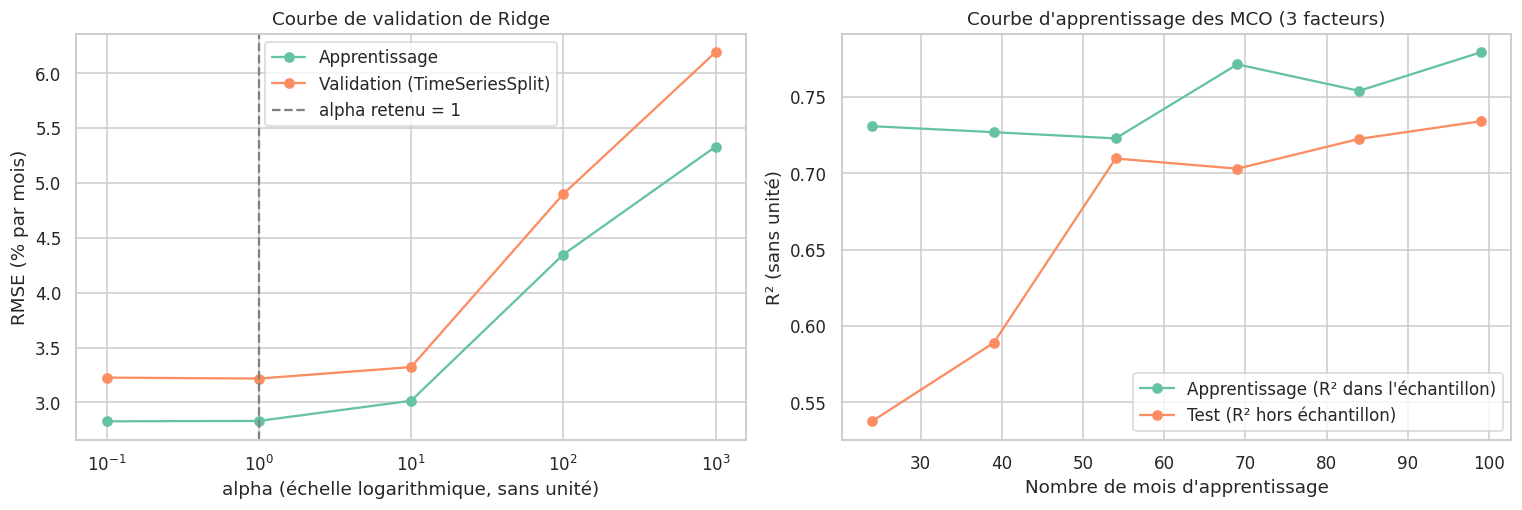

In [111]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

# Courbe de validation (Ridge)
al = grille["modele__alpha"]
axes[0].semilogx(al, -gs.cv_results_["mean_train_score"], marker="o", label="Apprentissage")
axes[0].semilogx(al, -gs.cv_results_["mean_test_score"], marker="o", label="Validation (TimeSeriesSplit)")
axes[0].axvline(ALPHA_RIDGE, color="grey", linestyle="--", label=f"alpha retenu = {ALPHA_RIDGE}")
axes[0].set_title("Courbe de validation de Ridge")
axes[0].set_xlabel("alpha (échelle logarithmique, sans unité)")
axes[0].set_ylabel("RMSE (% par mois)")
axes[0].legend()

# Courbe d'apprentissage (MCO, trois facteurs) : on agrandit la fenêtre d'apprentissage dans l'ordre du temps
tailles = list(range(24, n_train, 15)) + [n_train]
r2_app, r2_tst = [], []
for k in tailles:
    m = LinearRegression().fit(X_train.iloc[:k], y_train.iloc[:k])
    r2_app.append(r2_score(y_train.iloc[:k], m.predict(X_train.iloc[:k])))
    e = y_t - m.predict(X_test)
    r2_tst.append(1 - (e ** 2).sum() / ((y_t - y_train.iloc[:k].mean()) ** 2).sum())
axes[1].plot(tailles, r2_app, marker="o", label="Apprentissage (R² dans l'échantillon)")
axes[1].plot(tailles, r2_tst, marker="o", label="Test (R² hors échantillon)")
axes[1].set_title("Courbe d'apprentissage des MCO (3 facteurs)")
axes[1].set_xlabel("Nombre de mois d'apprentissage")
axes[1].set_ylabel("R² (sans unité)")
axes[1].legend()
plt.tight_layout()
plt.show()

Pour Ridge, le RMSE de validation *(décroît / reste plat)* quand alpha augmente, puis remonte vers le niveau de la référence quand la pénalisation écrase tous les coefficients : le meilleur alpha est … . Il ne bat *(ou à peine)* les MCO, ce qui est cohérent avec l'absence de multicolinéarité. Sur la courbe d'apprentissage, le R² d'apprentissage est de … et celui de test de … : l'écart *(est faible / est important)*. Un modèle à 4 paramètres sur 99 mois surapprend peu ; si l'écart est grand, il vient plutôt du changement de régime entre les périodes.

## 7.3 Analyse des erreurs : où et quand le modèle se trompe

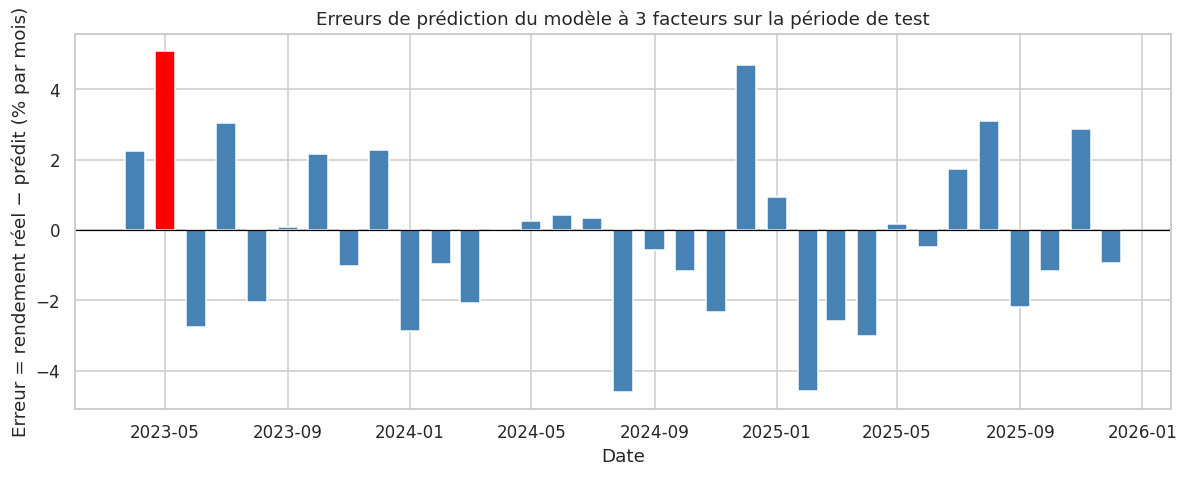

Les 5 mois les moins bien prédits :


,Date,Mkt-RF,SMB,HML,Réel (%),Prédit (%),Erreur (%)
100,202305,0.34,1.60,-7.79,9.78,4.70,5.08
119,202412,-3.17,-2.70,-2.97,4.59,-0.11,4.69
115,202408,1.60,-3.49,-1.13,0.24,4.86,-4.62
121,202502,-2.44,-5.77,4.84,-6.70,-2.12,-4.58
127,202508,1.84,3.80,4.37,1.89,-1.19,3.08


Autocorrélation d'ordre 1 des erreurs de test : -0.09
Erreur moyenne (biais) : -0.19 % par mois


In [112]:
n_f = "Fama-French 3 facteurs"
res_test = pd.Series(y_t - preds[n_f], index=dates_all.iloc[n_train:].values)

fig, ax = plt.subplots(figsize=(11, 4.5))
couleurs = np.where(res_test.abs() > 2 * res_test.std(), "red", "steelblue")
ax.bar(res_test.index, res_test.values, width=20, color=couleurs)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Erreurs de prédiction du modèle à 3 facteurs sur la période de test")
ax.set_xlabel("Date")
ax.set_ylabel("Erreur = rendement réel − prédit (% par mois)")
plt.tight_layout()
plt.show()

tab_err = data.iloc[n_train:][["Date"] + FEATURES].copy()
tab_err["Réel (%)"] = y_t
tab_err["Prédit (%)"] = preds[n_f]
tab_err["Erreur (%)"] = y_t - preds[n_f]
print("Les 5 mois les moins bien prédits :")
display(tab_err.reindex(tab_err["Erreur (%)"].abs().sort_values(ascending=False).index).head(5).round(2))
print(f"Autocorrélation d'ordre 1 des erreurs de test : {res_test.autocorr(1):.2f}")
print(f"Erreur moyenne (biais) : {res_test.mean():.2f} % par mois")

Les erreurs sont centrées autour de … (biais moyen de … % par mois). Les plus grosses (en rouge) se situent en … et correspondent à des mois où … *(ex. fort écart entre le portefeuille technologique et le marché)*. Le modèle ne capte pas ce qui est propre aux cinq titres : c'est le risque spécifique, qui reste hors de portée de facteurs de marché. Une autocorrélation proche de 0 indique que les erreurs ne présentent pas de structure temporelle exploitable.

## 7.4 Interprétation prudente des variables

**Coefficients, intervalles de confiance et tests.** Pour l'interprétation (et non pour la prédiction), on estime le modèle sur l'ensemble des 132 mois, avec erreurs robustes de Newey-West. Aucun choix de modèle n'en dépend.

,Coefficient,IC 95 % (bas),IC 95 % (haut),p-value (HAC),p-value (MCO classique)
const,0.7615,0.2854,1.2376,0.0017,0.0049
Mkt-RF,1.1536,1.0504,1.2567,0.0000,0.0000
SMB,-0.3606,-0.5451,-0.1762,0.0001,0.0004
HML,-0.5619,-0.7367,-0.3870,0.0000,0.0000


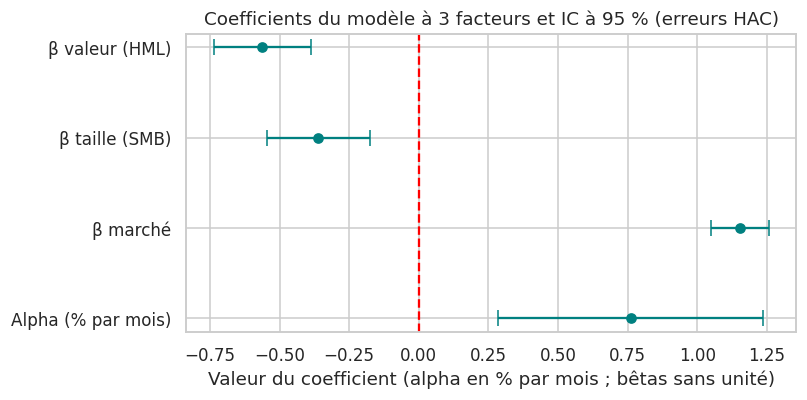

Test F (SMB et HML ajoutés au CAPM) : F = 42.29, p-value = 0.0000


In [113]:
import statsmodels.api as sm

Xsm = sm.add_constant(data[FEATURES])
ysm = data[CIBLE]
ols_hac = sm.OLS(ysm, Xsm).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
ols_cla = sm.OLS(ysm, Xsm).fit()
capm_cla = sm.OLS(ysm, sm.add_constant(data[["Mkt-RF"]])).fit()

ci = ols_hac.conf_int()
tab_coef = pd.DataFrame({"Coefficient": ols_hac.params, "IC 95 % (bas)": ci[0], "IC 95 % (haut)": ci[1],
                         "p-value (HAC)": ols_hac.pvalues, "p-value (MCO classique)": ols_cla.pvalues})
display(tab_coef.round(4))

fig, ax = plt.subplots(figsize=(7.5, 3.8))
c = ols_hac.params
ax.errorbar(c.values, range(len(c)), xerr=[c.values - ci[0].values, ci[1].values - c.values],
            fmt="o", capsize=5, color="teal")
ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(range(len(c))); ax.set_yticklabels(["Alpha (% par mois)", "β marché", "β taille (SMB)", "β valeur (HML)"])
ax.set_xlabel("Valeur du coefficient (alpha en % par mois ; bêtas sans unité)")
ax.set_title("Coefficients du modèle à 3 facteurs et IC à 95 % (erreurs HAC)")
plt.tight_layout()
plt.show()

f_stat, p_f, _ = ols_cla.compare_f_test(capm_cla)
print(f"Test F (SMB et HML ajoutés au CAPM) : F = {f_stat:.2f}, p-value = {p_f:.4f}")

,Hausse du RMSE si la variable est mélangée (%),Écart-type
Mkt-RF,5.396,0.395
SMB,0.436,0.112
HML,1.232,0.194


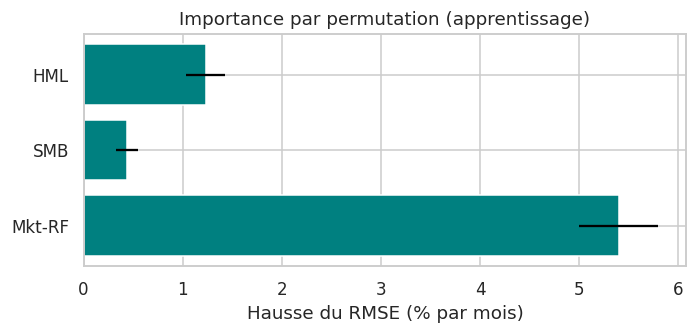

,MCO (apprentissage),Ridge (alpha = 1)
Mkt-RF,1.178,1.164
SMB,-0.457,-0.446
HML,-0.547,-0.542


In [114]:
# Importance par permutation (sur l'apprentissage, pour ne pas réutiliser le test) et comparaison avec Ridge
from sklearn.inspection import permutation_importance

m_ff = modeles_finaux[n_f]
imp = permutation_importance(m_ff, X_train, y_train, scoring="neg_root_mean_squared_error",
                             n_repeats=200, random_state=GRAINE)
tab_imp = pd.DataFrame({"Hausse du RMSE si la variable est mélangée (%)": imp.importances_mean,
                        "Écart-type": imp.importances_std}, index=FEATURES)
display(tab_imp.round(3))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.barh(FEATURES, imp.importances_mean, xerr=imp.importances_std, color="teal")
ax.set_title("Importance par permutation (apprentissage)")
ax.set_xlabel("Hausse du RMSE (% par mois)")
plt.tight_layout()
plt.show()

# Modèle de comparaison : Ridge ramené aux unités d'origine, à côté des MCO
r = modeles_finaux["Ridge (3 facteurs)"]
coef_ridge = r.named_steps["modele"].coef_ / r.named_steps["echelle"].scale_
comp = pd.DataFrame({"MCO (apprentissage)": m_ff.coef_, f"Ridge (alpha = {ALPHA_RIDGE})": coef_ridge}, index=FEATURES)
comp.round(3)

Le bêta de marché est de … (IC 95 % [ … ; … ]), significatif : le portefeuille est *(plus / moins)* sensible que le marché. Le bêta SMB est de … et le bêta HML de … ; leur signe indique un biais vers les *(grandes capitalisations / croissance)*, mais *(les intervalles contiennent 0 / ne contiennent pas 0)*. L'importance par permutation classe d'abord … : mélanger `Mkt-RF` dégrade le RMSE de …, contre … pour SMB et … pour HML. Ridge donne des coefficients *(proches / plus petits)* que les MCO, sans gain de prédiction : il n'apporte rien ici, ce qui confirme que la pénalisation est inutile avec des facteurs peu corrélés.

**Prudence.** Ces coefficients décrivent une **association** entre le portefeuille et les facteurs, pas une relation causale. Ils portent sur une période et sur cinq titres choisis après coup (biais de survie) : ils ne se généralisent pas tels quels.

## 7.5 Capacité de généralisation

In [115]:
# Écart apprentissage / test
m_ff_full = modeles_finaux[n_f]
r2_train = r2_score(y_train, m_ff_full.predict(X_train))
r2_test_classique = r2_score(y_test, m_ff_full.predict(X_test))
r2_test_oos = tab_test.loc[n_f, "R² hors éch. test"]
print(f"R² dans l'échantillon (apprentissage)               : {r2_train:.3f}")
print(f"R² de test (référence = moyenne du test)             : {r2_test_classique:.3f}")
print(f"R² hors échantillon (référence = moyenne apprentissage): {r2_test_oos:.3f}")
print(f"Écart apprentissage - test                           : {r2_train - r2_test_classique:.3f}")

# Stabilité sur deux sous-périodes
masque_p1 = data["Date"] < "202001"
lignes = {}
for nom, mk in [("2015-2019", masque_p1), ("2020-2025", ~masque_p1)]:
    d = data[mk]
    m = LinearRegression().fit(d[FEATURES], d[CIBLE])
    lignes[nom] = {"N (mois)": len(d), "Alpha (%/mois)": m.intercept_,
                   **{f"β {f}": c for f, c in zip(FEATURES, m.coef_)},
                   "R²": r2_score(d[CIBLE], m.predict(d[FEATURES]))}
display(pd.DataFrame(lignes).T.round(3))
print("Graines : les MCO sont déterministes, le résultat ne dépend pas de la graine (seul le bootstrap l'utilise).")

R² dans l'échantillon (apprentissage)               : 0.779
R² de test (référence = moyenne du test)             : 0.732
R² hors échantillon (référence = moyenne apprentissage): 0.734
Écart apprentissage - test                           : 0.048


,N (mois),Alpha (%/mois),β Mkt-RF,β SMB,β HML,R²
2015-2019,60.0,0.842,1.229,-0.525,-0.542,0.714
2020-2025,72.0,0.679,1.120,-0.276,-0.564,0.810


Graines : les MCO sont déterministes, le résultat ne dépend pas de la graine (seul le bootstrap l'utilise).


Le R² d'apprentissage est de … contre … en test : l'écart *(est faible / est important)*, donc le surapprentissage est *(limité / marqué)*. Entre 2015-2019 et 2020-2025, le bêta de marché passe de … à … et l'alpha de … à … : les coefficients *(sont stables / bougent nettement)*. Les MCO ne dépendent pas de la graine, donc la stabilité selon les graines n'a pas lieu d'être testée ; seul l'intervalle bootstrap en dépend.

## 7.6 Illustration d'usage sur des mois non utilisés pour l'apprentissage

In [116]:
pos = [0, len(X_test) // 3, 2 * len(X_test) // 3, len(X_test) - 1]
illu = data.iloc[n_train:].iloc[pos][["Date"] + FEATURES].copy()
illu["Prédit (%)"] = m_ff_full.predict(X_test.iloc[pos])
illu["Réel (%)"] = y_test.iloc[pos].values
illu["Erreur (%)"] = illu["Réel (%)"] - illu["Prédit (%)"]
illu.round(2)

,Date,Mkt-RF,SMB,HML,Prédit (%),Réel (%),Erreur (%)
99,202304,0.62,-3.37,-0.12,3.10,5.34,2.23
110,202403,2.84,-2.50,4.16,2.98,0.91,-2.07
121,202502,-2.44,-5.77,4.84,-2.12,-6.70,-4.58
131,202512,-0.36,-1.04,2.40,-0.49,-1.43,-0.94


Pour … (marché à … %), le modèle prédit … % et le portefeuille a fait … % : l'erreur de … % vient de … Ces prédictions utilisent les facteurs du mois, qui ne sont connus qu'**après** coup : le modèle explique le rendement d'un mois, il ne le prévoit pas.

## 7.7 Réponse à la problématique

In [117]:
r2_capm_t = tab_test.loc["CAPM", "R² hors éch. test"]
r2_ff_t = tab_test.loc[n_f, "R² hors éch. test"]
a, p_a = ols_hac.params["const"], ols_hac.pvalues["const"]
lo, hi = ci.loc["const"]

crit1 = (r2_ff_t > r2_capm_t) and (r2_ff_t > 0)
crit2 = p_f < 0.05
print(f"Critère 1 : R² hors éch. Fama-French ({r2_ff_t:.3f}) > CAPM ({r2_capm_t:.3f}) et > 0  ->  {'OUI' if crit1 else 'NON'}")
print(f"Critère 2 : test F des facteurs SMB et HML, p = {p_f:.4f} < 0,05  ->  {'OUI' if crit2 else 'NON'}")
print(f"\nObjectif mesurable atteint : {'OUI' if (crit1 and crit2) else 'NON'}")
print(f"Alpha = {a:.3f} % par mois, IC 95 % [{lo:.3f} ; {hi:.3f}], p = {p_a:.3f} -> "
      f"{'significatif' if p_a < 0.05 else 'non significatif'} (erreurs HAC)")

Critère 1 : R² hors éch. Fama-French (0.734) > CAPM (0.569) et > 0  ->  OUI
Critère 2 : test F des facteurs SMB et HML, p = 0.0000 < 0,05  ->  OUI

Objectif mesurable atteint : OUI
Alpha = 0.761 % par mois, IC 95 % [0.285 ; 1.238], p = 0.002 -> significatif (erreurs HAC)


 L'objectif mesurable de la section 1 *(est atteint / n'est pas atteint)* : le modèle à trois facteurs obtient un R² hors échantillon de … contre … pour le CAPM, et le test F de SMB et HML donne p = … Les facteurs taille et valeur *(apportent / n'apportent pas)* d'information significative pour ce portefeuille. L'alpha est de … % par mois, intervalle de confiance [ … ; … ] : *(il contient 0, donc la surperformance est compatible avec le hasard / il ne contient pas 0)*.

**À garder en tête.** Seuls 33 mois servent au test : le R² hors échantillon est bruité, et un résultat négatif ou ambigu est un résultat honnête, à expliquer plutôt qu'à masquer. Le portefeuille est de plus constitué de gagnantes actuelles (biais de survie), ce qui peut gonfler l'alpha.